In [92]:
# import dependencies
import numpy as np
import matplotlib.pyplot as plt

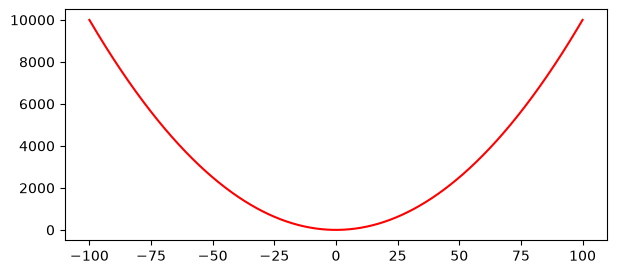

In [93]:
# create the function y=x^2 that 
x_quadratic = np.array(np.linspace(-100, 100, 50000))
y_quadratic = np.array(x_quadratic**2)  
# to do a column vector
x_quadratic.reshape(1,-1)
y_quadratic.reshape(1,-1)
# now we have all the points in a (50000,2) matrix
# here we could use np.hstack because they are already columns, if we didn't to .reshape(1,-1) np.column_stack would work but np.hstack wouldn't
quadratic_points = np.column_stack((x_quadratic, y_quadratic))
# print(quadratic_points.shape) #(50000, 2)

plt.figure(figsize=(7,3))
plt.plot(x_quadratic, y_quadratic, "r-")
plt.axis("Tight")
plt.show()

In [94]:
# know we will create the training data 
n = 20000 # points of training data
x_input = np.random.uniform(-100, 100, size = (n,1))
y_input = np.random.uniform(-1000, 11000, size = (n,1))

# here hstack also works because x and y are already columns
input = np.array(np.hstack((x_input, y_input))) # shape (5000,2)

"""
output_train = np.zeros((n,1))
for idx, row in enumerate(input_train):
    a, b = row[0], row[1]
    if b<a**2:
        output_train[idx]=1
    else:
        output_train[idx]=0
"""

# what is above is the same as this
output = (y_input < x_input**2).astype(int)

n_train = int(0.8*n)
# split the training and test data
input_training = input[:n_train]
input_test = input[n_train:]
output_training = output[:n_train]
output_test = output[n_train:]

# normalize the data
std_train = np.std(input_training, axis = 0)
std_train[std_train == 0] = 1e-8 # avoids division by zero if the std of a column is 0
mean_train = np.mean(input_training, axis = 0)
input_training = (input_training - mean_train) / std_train
input_test = (input_test - mean_train) / std_train


In [ ]:
# now we will solve the problem way 1 -> combine the perceptron in layers -> MLP
class MLP_binary:
    def __init__(self, input_size, hidden_size, output_size):
        # the input size is going to be multiply by column, thats why we use it to define the rows
        self.weights_input_hidden = np.random.randn(input_size, hidden_size)
        self.weights_hidden_output = np.random.randn(hidden_size, output_size)
        self.bias_hidden = np.zeros((1, hidden_size))
        self.bias_output = np.zeros((1, output_size))

    # defining 2 activation functions
    def relu(self, x):
        return np.maximum(0, x)
    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    # defining the derivative functions for the backpropagation
    def relu_derivative(self, x):
        return np.where(x > 0, 1, 0)
    
    
    def forward(self, input_data):
        # hidden layer with ReLU
        self.hidden_input = np.dot(input_data, self.weights_input_hidden) + self.bias_hidden
        self.hidden_output = self.relu(self.hidden_input)

        # Output Layer with Sigmoid
        self.final_input = np.dot(self.hidden_output, self.weights_hidden_output) + self.bias_output
        self.final_output = self.sigmoid(self.final_input) 
        return self.final_output

    def backpropagation(self, input_data, output, ground_truth, learning_rate):
        # to adjust by the number of the training data
        m = input_data.shape[0] 
        learning_rate = learning_rate / m


        output_error = output - ground_truth # derivative of sigmoide function in the loss in the last layer
        # here we use the derivative of relu
        hidden_error = np.dot(output_error, self.weights_hidden_output.T) * self.relu_derivative(self.hidden_input)

        self.weights_hidden_output -= learning_rate * np.dot(self.hidden_output.T, output_error)
        self.bias_output -= learning_rate * np.sum(output_error, axis = 0, keepdims=True)
        self.weights_input_hidden -= learning_rate * np.dot(input_data.T, hidden_error)
        self.bias_hidden -= learning_rate * np.sum(hidden_error, axis = 0, keepdims=True)

    def train(self, input_data, ground_truth, epochs, learning_rate):
        for epoch in range(epochs):
            output_predicted = self.forward(input_data)
            self.backpropagation(input_data, output_predicted, ground_truth, learning_rate)
            # print the error at each 5 epochs
            if (epoch+1) % 500 == 0:
                eps = 1e-15
                output_stable = np.clip(output_predicted, eps, 1 - eps) # to not do log(0) or log(1)
                # Binary Cross-Entropy
                loss = -np.mean(ground_truth * np.log(output_stable) + (1 - ground_truth) * np.log(1 - output_stable))
                accuracy = np.mean(np.round(output_predicted) == ground_truth)
                print(f'Epoch {epoch+1}, Loss: {loss:.4f}, Accuracy {accuracy:.4f}')

    def predict(self, input):
        output = self.forward(input)
        return np.round(output, 0)

WAY_1 = MLP_binary(2,100,1)
WAY_1.train(input_training, output_training, 10000, 0.1)

predicted_test = WAY_1.predict(input_test)
accuracy_test = np.mean(np.round(predicted_test == output_test))
print(f'Accuracy {accuracy_test:.4f}')
    

Epoch 500, Loss: 0.0710, Accuracy 0.9879
Epoch 1000, Loss: 0.0551, Accuracy 0.9916
Epoch 1500, Loss: 0.0470, Accuracy 0.9925
Epoch 2000, Loss: 0.0415, Accuracy 0.9940
Epoch 2500, Loss: 0.0374, Accuracy 0.9953
Epoch 3000, Loss: 0.0344, Accuracy 0.9959
Epoch 3500, Loss: 0.0321, Accuracy 0.9959
Epoch 4000, Loss: 0.0300, Accuracy 0.9963


In [ ]:
# solving the problem way two